In [1]:
import pandas as pd
import numpy as np
import os
import json
import pandas_datareader.data as web   # my local kernel Python 3.10.7 
import matplotlib.pyplot as plt  # unavailable?  do: 1. pip uninstall matplotlib # 2. python3 -m pip install matplotlib
%matplotlib inline
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
import datetime
import io
pd.set_option('display.max_columns', None)
import warnings
import seaborn as sns
import scipy
from scipy import stats
warnings.filterwarnings("ignore")
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import talib as ta

import scipy
from scipy import stats

C:\Users\tonya\AppData\Local\Temp\ipykernel_20520\290755842.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
def from_Tick(csvFile, interval, chart, originalPrice):
    tit = str(csvFile).replace('C:\BidAskRepo\\', '').replace('older_repo2022\\', '').replace('Globex_', '').replace('.csv','').strip()
    # tit = str(csvFile).replace('C:\\BidAskRepo\\', '').replace(' Globex_', '_').replace('.csv','')
    periodGlobal = interval
    columns = ['DateTime', 'Vol', 'BidAsk', 'Bid', 'Ask', 'Price']
    mapping = {'AtBid': -1, 'AtAsk': 1, 'BelowBid': -2, 'AboveAsk': 2, 'BetweenBidAsk':0 }  
    l = pd.read_csv(csvFile, names = columns, index_col='DateTime', parse_dates= True)  
    l = l.sort_index()
    l = l.replace({'BidAsk': mapping})
    l['Scaled'] = stats.zscore(l.Price)
    # l['Price'] = l.Price
    print('Shape: ', l.shape)
    del l['Ask']
    del l['Bid']
    if chart:
        ti = str(l.index[0])[0:10]
        # print('ti is: ', ti)  
        p1 = ti + ' 06:00:00'
        p2 = ti + ' 16:30:00'
        p11 = ti + ' 09:00:00'
        p12 = ti + ' 10:00:00'
        # print('p1, p2 are: ', p1, p2)
        l.loc[p1:p2].plot(y='Scaled', figsize=(16,4)) 
        ti = str(l.index[0])[0:10]
        plt.title(tit)
        plt.axhline(y= l.loc[p11 : p12]['Scaled'].max(), xmin = 0.32, xmax = 0.92, color = 'blue', linestyle = 'dashed', label="Open-High", alpha=0.3)
        plt.axhline(y= l.loc[p11 : p12]['Scaled'].min(), xmin = 0.32, xmax = 0.92, color = 'red', linestyle = 'dashed', label="Open-Low", alpha=0.3)
        plt.axhline(y= 0, xmin = 0.99, xmax = 0.001, color = 'black', linestyle = 'dashed', label="0", linewidth= 1)
        plt.axvline(x=  ti + ' 07:00:00')
        plt.axvline(x=  ti + ' 09:30:00', ymax = 1, linewidth= 1.5, color='red', alpha=0.7)
        plt.axvline(x=  ti + ' 10:00:00', ymax = 1, linewidth= 1.5, color='red', alpha=0.7)
        plt.axvline(x=  ti + ' 09:45:00', ymax = 1, linewidth= 45, color='blue', alpha=0.2)
        plt.axvline(x=  ti + ' 11:00:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 11:10:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 11:20:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 11:30:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 12:00:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 13:00:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 14:00:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 15:00:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 16:00:00', color= 'red')
        plt.grid()
    if originalPrice:  
        ti = str(l.index[0])[0:10]
        # print('ti is: ', ti)  
        p1 = ti + ' 06:00:00'
        p2 = ti + ' 16:30:00'
        p11 = ti + ' 09:00:00'
        p12 = ti + ' 10:00:00'
        # print('p1, p2 are: ', p1, p2)
        l.loc[p1:p2].plot(y='Price', figsize=(16,4)) 
        ti = str(l.index[0])[0:10]
        plt.title(tit)
        plt.axhline(y= l.loc[p11 : p12]['Price'].max(), xmin = 0.32, xmax = 0.92, color = 'blue', linestyle = 'dashed', label="Open-High", alpha=0.3)
        plt.axhline(y= l.loc[p11 : p12]['Price'].min(), xmin = 0.32, xmax = 0.92, color = 'red', linestyle = 'dashed', label="Open-Low", alpha=0.3)
        # plt.axhline(y= 0, xmin = 0.99, xmax = 0.001, color = 'black', linestyle = 'dashed', label="0", linewidth= 1)
        plt.axvline(x=  ti + ' 07:00:00')
        plt.axvline(x=  ti + ' 09:30:00', ymax = 1, linewidth= 1.5, color='red', alpha=0.7)
        plt.axvline(x=  ti + ' 10:00:00', ymax = 1, linewidth= 1.5, color='red', alpha=0.7)
        plt.axvline(x=  ti + ' 09:45:00', ymax = 1, linewidth= 45, color='blue', alpha=0.2)
        plt.axvline(x=  ti + ' 11:00:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 11:10:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 11:20:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 11:30:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 12:00:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 13:00:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 14:00:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 15:00:00', ymax = 1, linewidth= 1.5, color='b', alpha=0.1)
        plt.axvline(x=  ti + ' 16:00:00', color= 'red')
        plt.grid()  
    return l

Shape:  (292227, 6)


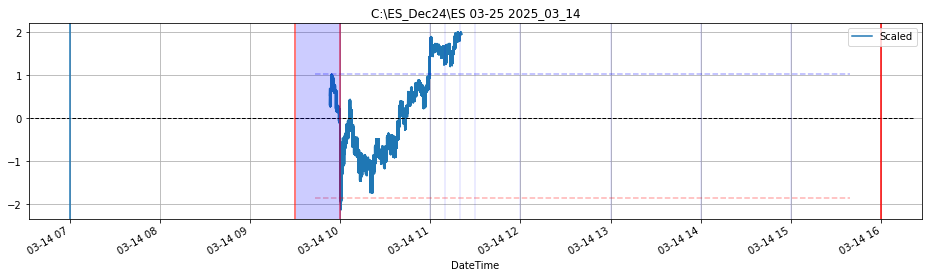

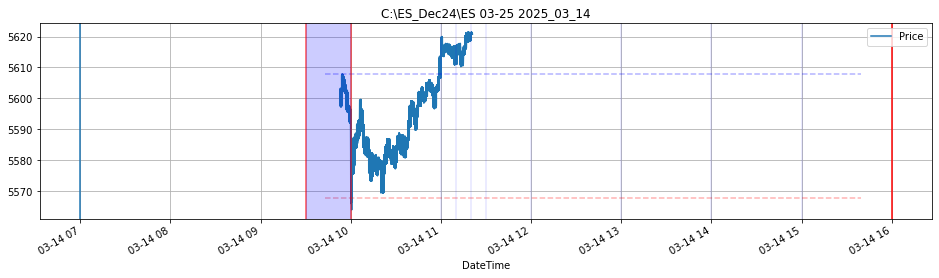

In [3]:
df = from_Tick(r"C:\ES_Dec24\ES 03-25 Globex_2025_03_14.csv", '1Min', True, True)

Shape:  (350188, 6)


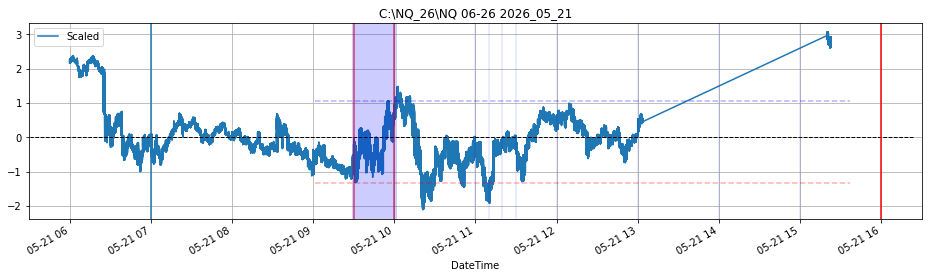

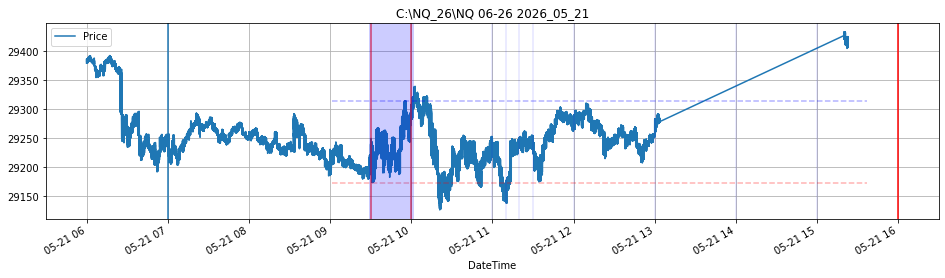

In [4]:
f = r"C:\NQ_26\NQ 06-26 Globex_2026_05_21.csv"
df = from_Tick(f, '10S', True, True)
# df.head(30)

In [5]:
# Calculate the difference in prices over each interval
df['Price_Diff'] = df['Price'].diff()

# Since we've resampled to 10-second intervals, we know that the time difference is 10 seconds
df['Rate_of_Change'] = df['Price_Diff'] / 10

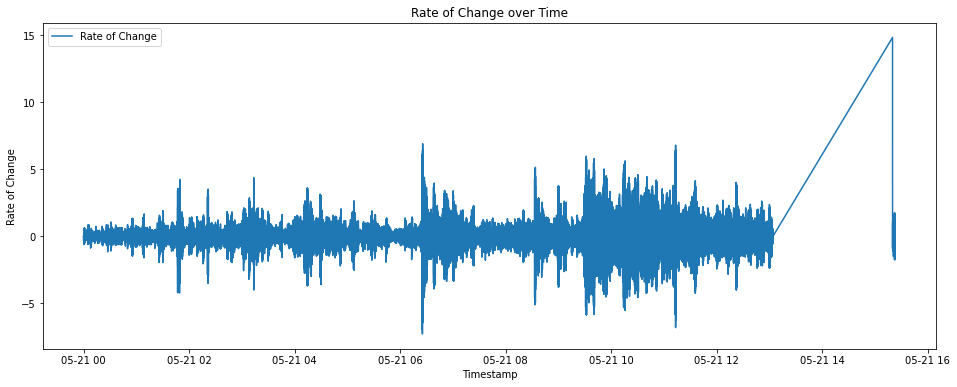

In [6]:
# Assuming 'Rate_of_Change' is calculated and is in df_resampled DataFrame
plt.figure(figsize=(16, 6))

# Plotting Rate_of_Change over time
plt.plot(df.index, df['Rate_of_Change'], label='Rate of Change')

# Providing labels and title
plt.xlabel('Timestamp')
plt.ylabel('Rate of Change')
plt.title('Rate of Change over Time')
plt.legend()

# Displaying the plot
plt.show()

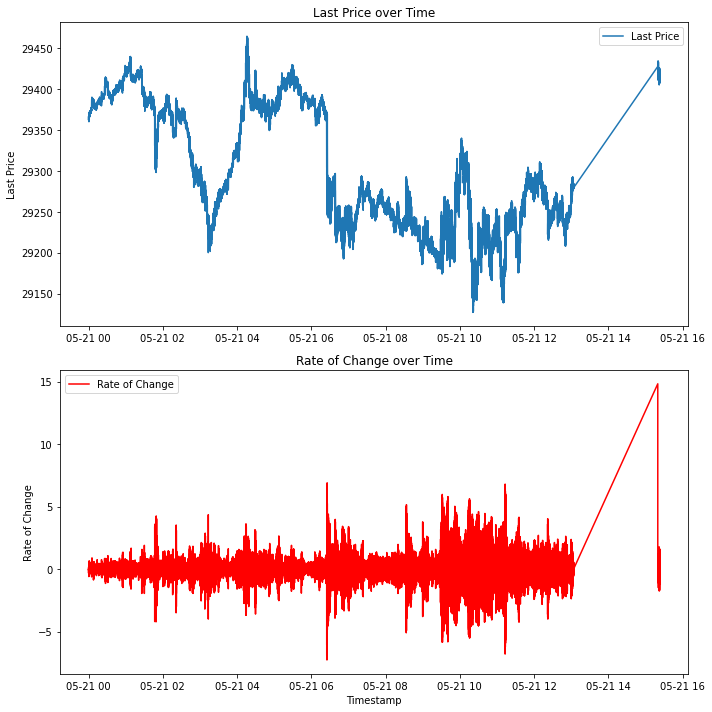

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(10, 10))

# Plotting Last Price over time
axs[0].plot(df.index, df['Price'], label='Last Price')
axs[0].set_ylabel('Last Price')
axs[0].set_title('Last Price over Time')
axs[0].legend()

# Plotting Rate of Change over time
axs[1].plot(df.index, df['Rate_of_Change'], label='Rate of Change', color='red')
axs[1].set_xlabel('Timestamp')
axs[1].set_ylabel('Rate of Change')
axs[1].set_title('Rate of Change over Time')
axs[1].legend()

# Displaying the plot
plt.tight_layout()
plt.show()

In [8]:
df.head()

,Vol,BidAsk,Price,Scaled,Price_Diff,Rate_of_Change
DateTime,,,,,,
2026-05-21 00:00:00,1,-1,29366.00,1.927288,NaN,NaN
2026-05-21 00:00:00,1,-1,29366.00,1.927288,0.00,0.000
2026-05-21 00:00:05,1,1,29366.25,1.931511,0.25,0.025
2026-05-21 00:00:07,1,1,29363.00,1.876612,-3.25,-0.325
2026-05-21 00:00:08,1,-1,29362.00,1.859721,-1.00,-0.100


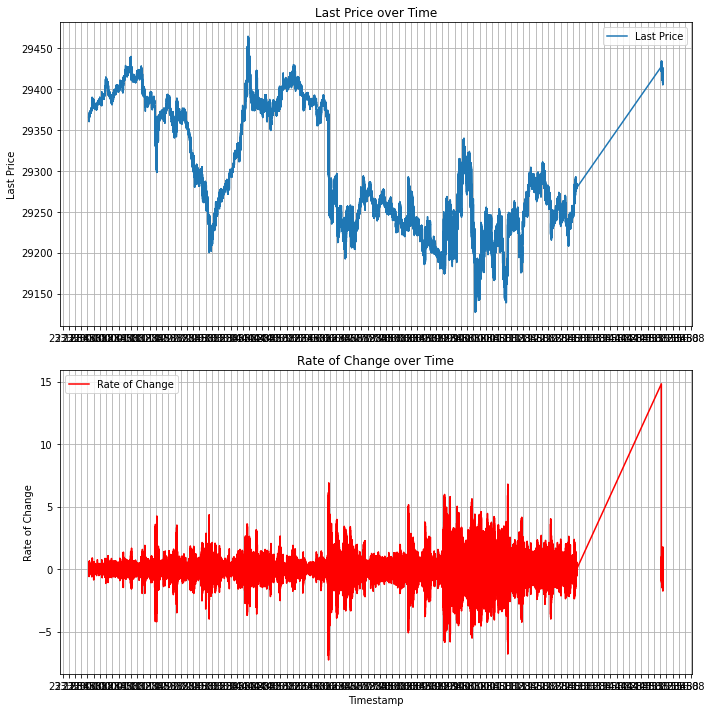

In [9]:
import matplotlib.dates as mdates

fig, axs = plt.subplots(2, 1, figsize=(10, 10))

# Plotting Last Price over time
axs[0].plot(df.index, df['Price'], label='Last Price')
axs[0].set_ylabel('Last Price')
axs[0].set_title('Last Price over Time')
axs[0].legend()

axs[0].xaxis.set_major_locator(mdates.MinuteLocator(interval=10))  # to get a tick every 5 minutes
axs[0].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # format of the timestamp
axs[0].grid(True)

# Plotting Rate of Change over time
axs[1].plot(df.index, df['Rate_of_Change'], label='Rate of Change', color='red')
axs[1].set_xlabel('Timestamp')
axs[1].set_ylabel('Rate of Change')
axs[1].set_title('Rate of Change over Time')
axs[1].legend()

axs[1].xaxis.set_major_locator(mdates.MinuteLocator(interval=10))  # to get a tick every 5 minutes
axs[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # format of the timestamp
axs[1].grid(True)

# Displaying the plot
plt.tight_layout()
plt.show()

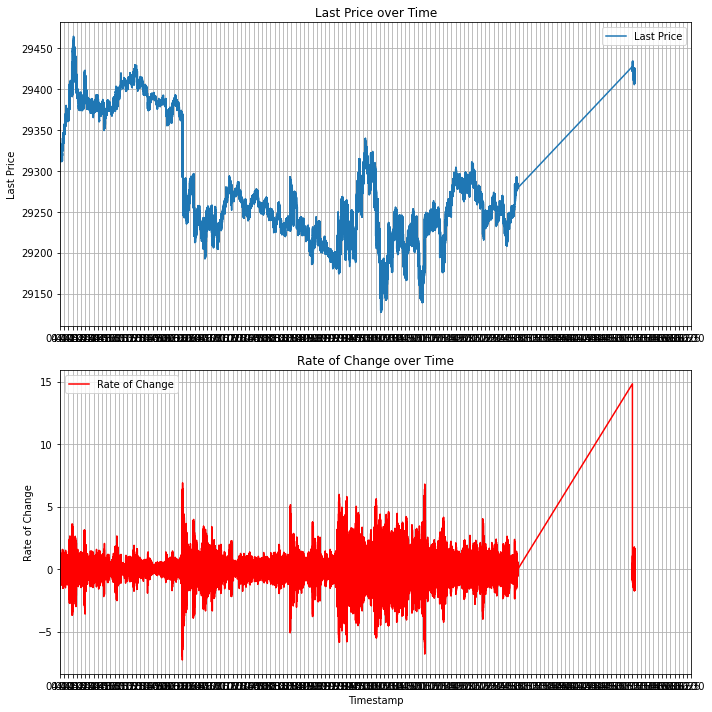

In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime

fig, axs = plt.subplots(2, 1, figsize=(10, 10))

# Set start and end of the interval
start_time = datetime.strptime('2026-05-21 04:00:00', '%Y-%m-%d %H:%M:%S')
end_time = datetime.strptime('2026-05-21 16:30:00', '%Y-%m-%d %H:%M:%S')

# Plotting Last Price over time
axs[0].plot(df.index, df['Price'], label='Last Price')
axs[0].set_ylabel('Last Price')
axs[0].set_title('Last Price over Time')
axs[0].legend()

axs[0].xaxis.set_major_locator(mdates.MinuteLocator(interval=5))  # to get a tick every 5 minutes
axs[0].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # format of the timestamp
axs[0].grid(True)

# Setting the x-axis limits
axs[0].set_xlim([start_time, end_time])

# Plotting Rate of Change over time
axs[1].plot(df.index, df['Rate_of_Change'], label='Rate of Change', color='red')
axs[1].set_xlabel('Timestamp')
axs[1].set_ylabel('Rate of Change')
axs[1].set_title('Rate of Change over Time')
axs[1].legend()

axs[1].xaxis.set_major_locator(mdates.MinuteLocator(interval=5))  # to get a tick every 5 minutes
axs[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # format of the timestamp
axs[1].grid(True)

# Setting the x-axis limits
axs[1].set_xlim([start_time, end_time])

# Displaying the plot
plt.tight_layout()
plt.show()


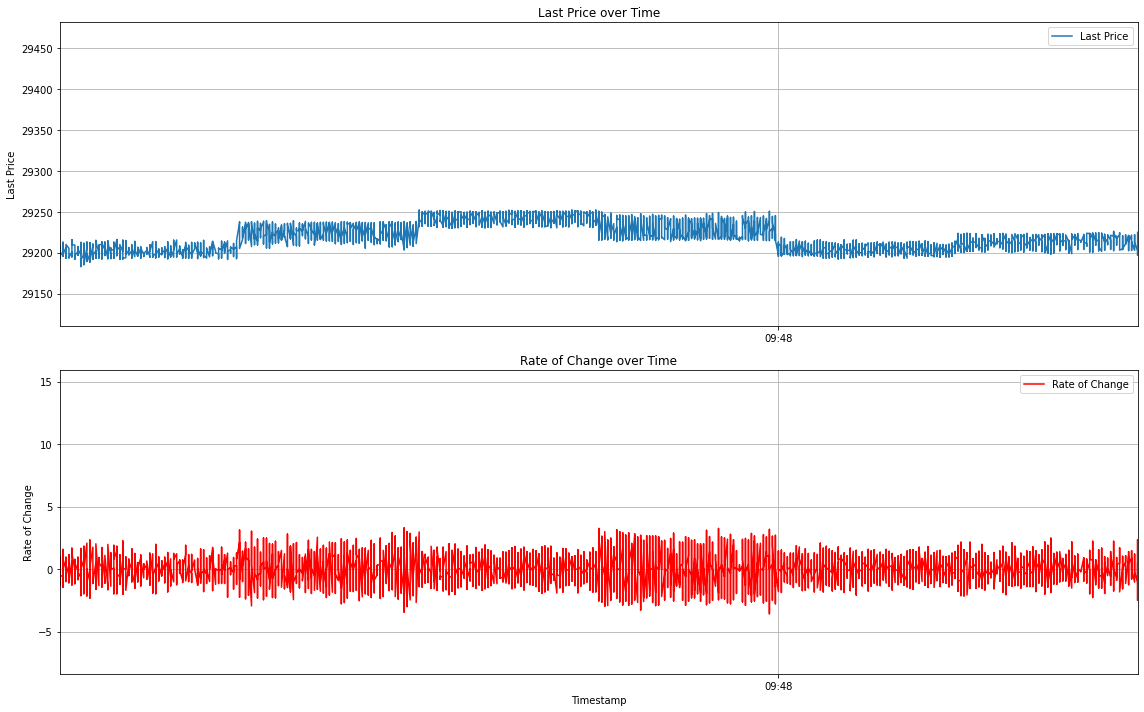

In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime

fig, axs = plt.subplots(2, 1, figsize=(16, 10))

# Set start and end of the interval
start_time = datetime.strptime('2026-05-21 09:44:00', '%Y-%m-%d %H:%M:%S')
end_time = datetime.strptime('2026-05-21 09:50:00', '%Y-%m-%d %H:%M:%S')

# Plotting Last Price over time
axs[0].plot(df.index, df['Price'], label='Last Price')
axs[0].set_ylabel('Last Price')
axs[0].set_title('Last Price over Time')
axs[0].legend()

axs[0].xaxis.set_major_locator(mdates.MinuteLocator(interval=5))  # to get a tick every 5 minutes
axs[0].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # format of the timestamp
axs[0].grid(True)

# Setting the x-axis limits
axs[0].set_xlim([start_time, end_time])

# Auto-scale on the y-axis
axs[0].autoscale_view(scalex=True, scaley=True)

# Plotting Rate of Change over time
axs[1].plot(df.index, df['Rate_of_Change'], label='Rate of Change', color='red')
axs[1].set_xlabel('Timestamp')
axs[1].set_ylabel('Rate of Change')
axs[1].set_title('Rate of Change over Time')
axs[1].legend()

axs[1].xaxis.set_major_locator(mdates.MinuteLocator(interval=5))  # to get a tick every 5 minutes
axs[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # format of the timestamp
axs[1].grid(True)

# Setting the x-axis limits
axs[1].set_xlim([start_time, end_time])

# Auto-scale on the y-axis
axs[1].autoscale_view(scalex=True, scaley=True)

# Displaying the plot
plt.tight_layout()
plt.show()


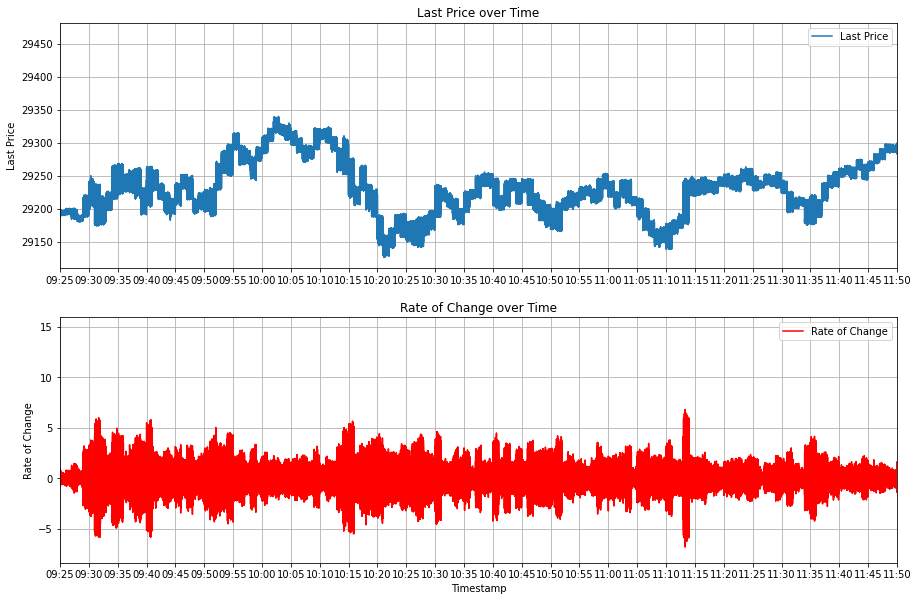

In [12]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime

fig, axs = plt.subplots(2, 1, figsize=(15, 10))

# Set start and end of the interval
start_time = datetime.strptime('2026-05-21 09:25:00', '%Y-%m-%d %H:%M:%S')
end_time = datetime.strptime('2026-05-21 11:50:00', '%Y-%m-%d %H:%M:%S')

# Plotting Last Price over time
axs[0].plot(df.index, df['Price'], label='Last Price')
axs[0].set_ylabel('Last Price')
axs[0].set_title('Last Price over Time')
axs[0].legend()

axs[0].xaxis.set_major_locator(mdates.MinuteLocator(interval=5))  # to get a tick every 5 minutes
axs[0].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # format of the timestamp
axs[0].grid(True)

# Setting the x-axis limits
axs[0].set_xlim([start_time, end_time])

# Auto-scale on the y-axis
axs[0].autoscale_view(scalex= False, scaley= True)

# Plotting Rate of Change over time
axs[1].plot(df.index, df['Rate_of_Change'], label='Rate of Change', color='red')
axs[1].set_xlabel('Timestamp')
axs[1].set_ylabel('Rate of Change')
axs[1].set_title('Rate of Change over Time')
axs[1].legend()

axs[1].xaxis.set_major_locator(mdates.MinuteLocator(interval=5))  # to get a tick every 5 minutes
axs[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # format of the timestamp
axs[1].grid(True)

# Setting the x-axis limits
axs[1].set_xlim([start_time, end_time])

# Auto-scale on the y-axis
axs[1].autoscale_view(scalex=False, scaley=True)

# Adjust the spacing between subplots
plt.subplots_adjust(top=0.80, bottom=0.05)

# Displaying the plot
plt.show()
